# MÓDULO 13 - Projeto: Fundamentos da Descoberta de Dados
Análise estatística descritiva e visual da base de produtos de um supermercado do Chile.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import squarify

os.makedirs('graficos', exist_ok=True)
pd.options.display.float_format = '{:,.2f}'.format

## Carga dos dados
O arquivo CSV está separado por **vírgula** (não ponto e vírgula).

In [2]:
df = pd.read_csv('MODULO7_PROJETOFINAL_BASE_SUPERMERCADO.csv')
print(df.shape)
df.head(10)

(1107, 7)


,title,Marca,Preco_Normal,Preco_Desconto,Preco_Anterior,Desconto,Categoria
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,19788,0,0,0,lacteos
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,18228,0,0,0,lacteos
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,18228,0,0,0,lacteos
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,18228,0,0,0,lacteos
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
5,"Pack 12 un, Leche sin lactosa frutilla 1 L",Loncoleche,17988,0,0,0,lacteos
6,"Pack 12 un, Leche saborizada light chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
7,"Pack 12 un, Leche saborizada frutilla 1 L",Colun,17388,0,0,0,lacteos
8,"Pack 12 un, Leche saborizada vainilla 1 L",Colun,17388,0,0,0,lacteos
9,"Pack 12 un, Leche saborizada manjar 1 L",Colun,17388,0,0,0,lacteos


### Qualidade dos dados: `Preco_Normal = 0`

In [3]:
zeros = (df['Preco_Normal'] == 0)
print(f'Linhas com Preco_Normal = 0: {zeros.sum()} de {len(df)} ({zeros.mean():.1%})')
print('Dessas, com Preco_Desconto > 0:', (zeros & (df['Preco_Desconto'] > 0)).sum())
df.loc[zeros].groupby('Categoria').size().rename('zeros_por_categoria')

Linhas com Preco_Normal = 0: 294 de 1107 (26.6%)
Dessas, com Preco_Desconto > 0: 244


Categoria
belleza-y-cuidado-personal    93
comidas-preparadas            10
congelados                    71
instantaneos-y-sopas          20
lacteos                       95
verduras                       5
Name: zeros_por_categoria, dtype: int64

Um preço normal igual a 0 não é um preço real: são produtos cujo valor aparece apenas em `Preco_Desconto` (ou sem preço normal registrado). Incluir esses zeros puxaria média e mediana para baixo e inflaria o desvio padrão.

**Decisão:** nas estatísticas de `Preco_Normal` (itens 1 a 3) tratamos 0 como dado ausente e usamos só preços > 0. Mostramos também a versão com todos os registros para comparação. Para o desconto (item 4 e 5) mantemos todas as linhas, pois `Desconto = 0` significa de fato "sem desconto".

In [4]:
df_preco = df[df['Preco_Normal'] > 0].copy()
print(len(df_preco), 'linhas com preço normal válido')

813 linhas com preço normal válido


# 1 - Média e mediana de `Preco_Normal` por categoria

In [5]:
stats = df_preco.groupby('Categoria')['Preco_Normal'].agg(
    n='count', media='mean', mediana='median', desvio_padrao='std')
stats['media_menos_mediana'] = stats['media'] - stats['mediana']
stats['razao_media_mediana'] = stats['media'] / stats['mediana']
stats['media_vs_mediana'] = stats['media_menos_mediana'].apply(
    lambda d: 'média ACIMA da mediana' if d > 0 else 'média ABAIXO da mediana')
stats.sort_values('razao_media_mediana', ascending=False)

,n,media,mediana,desvio_padrao,media_menos_mediana,razao_media_mediana,media_vs_mediana
Categoria,,,,,,,
lacteos,352,"3,028.96","1,719.50","4,198.57","1,309.46",1.76,média ACIMA da mediana
instantaneos-y-sopas,37,"1,179.27",689.00,"1,276.22",490.27,1.71,média ACIMA da mediana
frutas,19,"1,724.47","1,195.00","1,639.15",529.47,1.44,média ACIMA da mediana
belleza-y-cuidado-personal,146,"2,919.66","2,179.00","2,162.65",740.66,1.34,média ACIMA da mediana
verduras,59,"1,457.14","1,250.00",972.23,207.14,1.17,média ACIMA da mediana
comidas-preparadas,36,"3,954.78","3,740.00","1,322.33",214.78,1.06,média ACIMA da mediana
congelados,164,"3,020.67","2,954.00","1,904.48",66.67,1.02,média ACIMA da mediana


In [6]:
# Comparação: com todos os registros (incluindo zeros)
comp = df.groupby('Categoria')['Preco_Normal'].agg(media='mean', mediana='median', desvio_padrao='std')
comp

,media,mediana,desvio_padrao
Categoria,,,
belleza-y-cuidado-personal,"1,783.56","1,569.00","2,210.04"
comidas-preparadas,"3,095.04","3,290.00","2,019.91"
congelados,"2,108.04","1,519.00","2,111.54"
frutas,"1,724.47","1,195.00","1,639.15"
instantaneos-y-sopas,765.49,439.00,"1,170.23"
lacteos,"2,385.22",989.00,"3,925.82"
verduras,"1,343.30","1,180.00","1,012.70"


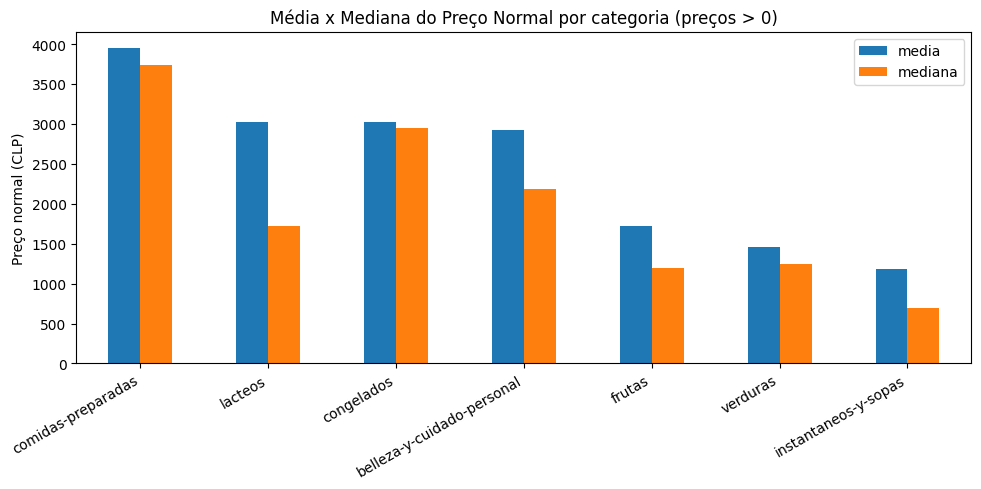

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
s = stats[['media', 'mediana']].sort_values('media', ascending=False)
s.plot(kind='bar', ax=ax, color=['#1f77b4', '#ff7f0e'])
ax.set_title('Média x Mediana do Preço Normal por categoria (preços > 0)')
ax.set_ylabel('Preço normal (CLP)'); ax.set_xlabel('')
plt.xticks(rotation=30, ha='right'); plt.tight_layout()
plt.savefig('graficos/00_media_mediana_por_categoria.png', dpi=150); plt.show()

**Categorias:** todas têm média acima da mediana (distribuições assimétricas à direita, puxadas por preços altos). O contraste é maior em `lacteos` (média ≈ 1,76× a mediana), `instantaneos-y-sopas` (≈ 1,71×) e `frutas` (≈ 1,44×). Em `comidas-preparadas` e `congelados` as duas medidas ficam bem próximas (≈ 1,06× e ≈ 1,02×), indicando distribuição mais simétrica. Veja a tabela acima para os valores exatos.

# 2 - Desvio padrão por categoria

In [8]:
dp = stats[['media', 'mediana', 'desvio_padrao']].sort_values('desvio_padrao', ascending=False)
dp['coef_variacao'] = dp['desvio_padrao'] / dp['media']
cat_max = dp.index[0]
print('Categoria com maior desvio padrão:', cat_max)
dp

Categoria com maior desvio padrão: lacteos


,media,mediana,desvio_padrao,coef_variacao
Categoria,,,,
lacteos,"3,028.96","1,719.50","4,198.57",1.39
belleza-y-cuidado-personal,"2,919.66","2,179.00","2,162.65",0.74
congelados,"3,020.67","2,954.00","1,904.48",0.63
frutas,"1,724.47","1,195.00","1,639.15",0.95
comidas-preparadas,"3,954.78","3,740.00","1,322.33",0.33
instantaneos-y-sopas,"1,179.27",689.00,"1,276.22",1.08
verduras,"1,457.14","1,250.00",972.23,0.67


**Comportamento:** `lacteos` tem o maior desvio padrão e também a maior distância entre média e mediana (média muito maior que a mediana). Isso indica que poucos produtos muito caros (ex.: packs de 12 unidades) elevam a média e a dispersão, enquanto a maioria dos itens custa bem menos, perto da mediana. Em `belleza-y-cuidado-personal` (2º maior desvio) a média também fica acima da mediana, mas de forma bem mais branda (≈ 1,34×). Já `congelados` (3º maior desvio) tem média e mediana quase iguais: a dispersão ali vem de uma faixa ampla de preços, não de poucos valores extremos. `verduras`, com o menor desvio, tem média e mediana próximas.

# 3 - Boxplot de `Preco_Normal` da categoria com maior desvio padrão

count      352.00
mean     3,028.96
std      4,198.57
min        209.00
25%        559.00
50%      1,719.50
75%      2,929.00
max     19,788.00
Name: Preco_Normal, dtype: float64

Q1=559  Q3=2929  IQR=2370  limite superior=6484  limite inferior=-2996


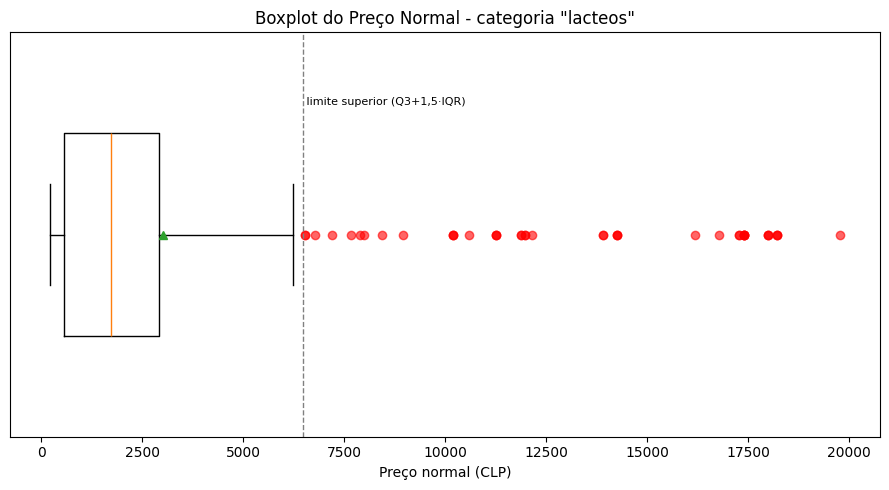

In [9]:
dados = df_preco.loc[df_preco['Categoria'] == cat_max, 'Preco_Normal']
q1, q3 = dados.quantile([0.25, 0.75]); iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(dados.describe())
print(f'\nQ1={q1:.0f}  Q3={q3:.0f}  IQR={iqr:.0f}  limite superior={lim_sup:.0f}  limite inferior={lim_inf:.0f}')

fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(dados, vert=False, showmeans=True, widths=0.5,
           flierprops=dict(marker='o', markerfacecolor='red', markeredgecolor='red', alpha=.6))
ax.set_title(f'Boxplot do Preço Normal - categoria "{cat_max}"')
ax.set_xlabel('Preço normal (CLP)'); ax.set_yticks([])
ax.axvline(lim_sup, color='gray', ls='--', lw=1); ax.text(lim_sup, 1.32, ' limite superior (Q3+1,5·IQR)', fontsize=8)
plt.tight_layout(); plt.savefig('graficos/01_boxplot_lacteos.png', dpi=150); plt.show()

**Interpretação:** a caixa (Q1 ≈ 559 a Q3 ≈ 2.929) concentra a metade central dos produtos na faixa baixa de preços, com a mediana (≈ 1.720) na metade esquerda da caixa e a média (triângulo verde, ≈ 3.029) à direita dela. O bigode superior e os pontos isolados se estendem muito para a direita (até 19.788): distribuição fortemente assimétrica à direita. Há **muitos outliers superiores (42, cerca de 12% dos produtos)** e nenhum inferior.

# 4 - Outliers do boxplot

In [10]:
outliers = df_preco[(df_preco['Categoria'] == cat_max) &
                    ((df_preco['Preco_Normal'] > lim_sup) | (df_preco['Preco_Normal'] < lim_inf))]
print(f'{len(outliers)} outliers ({len(outliers)/len(dados):.1%} dos {len(dados)} produtos de {cat_max})')
print(f'Menor outlier: {outliers.Preco_Normal.min()}  |  Maior outlier: {outliers.Preco_Normal.max()}')
outliers.sort_values('Preco_Normal', ascending=False)[['title', 'Marca', 'Preco_Normal']].reset_index(drop=True)

42 outliers (11.9% dos 352 produtos de lacteos)
Menor outlier: 6534  |  Maior outlier: 19788


,title,Marca,Preco_Normal
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,19788
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,18228
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,18228
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,18228
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,17988
5,"Pack 12 un, Leche sin lactosa frutilla 1 L",Loncoleche,17988
6,"Pack 12 un, Leche saborizada light chocolate 1 L",Loncoleche,17988
7,"Pack 12 un, Leche saborizada frutilla 1 L",Colun,17388
8,"Pack 12 un, Leche saborizada vainilla 1 L",Colun,17388
9,"Pack 12 un, Leche saborizada manjar 1 L",Colun,17388


In [11]:
outliers.groupby('Marca').size().sort_values(ascending=False).head(10)

Marca
Colun           11
Loncoleche      11
Soprole          6
Cuisine & Co     5
Nido             4
Surlat           2
Svelty           2
Calo             1
dtype: int64

# 5 - Gráfico de barras: média de desconto por categoria

Categoria
congelados                   154.03
belleza-y-cuidado-personal   123.08
comidas-preparadas            43.48
lacteos                       17.41
frutas                         0.00
instantaneos-y-sopas           0.00
verduras                       0.00
Name: Desconto, dtype: float64


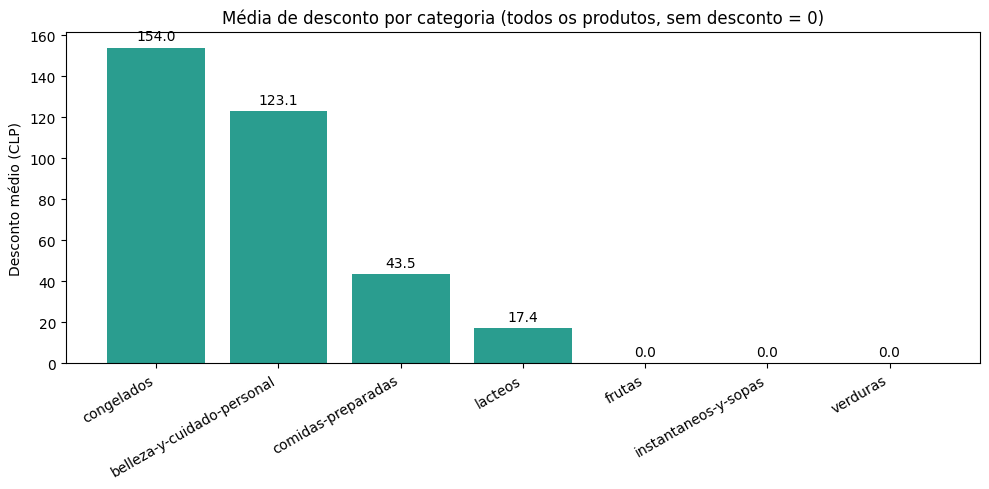

In [12]:
desc_cat = df.groupby('Categoria')['Desconto'].mean().sort_values(ascending=False)
print(desc_cat)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(desc_cat.index, desc_cat.values, color='#2a9d8f')
ax.bar_label(bars, fmt='%.1f', padding=3)
ax.set_title('Média de desconto por categoria (todos os produtos, sem desconto = 0)')
ax.set_ylabel('Desconto médio (CLP)'); plt.xticks(rotation=30, ha='right')
plt.tight_layout(); plt.savefig('graficos/02_barras_desconto_categoria.png', dpi=150); plt.show()

In [13]:
# Complemento: média considerando apenas produtos que tiveram desconto
df[df['Desconto'] > 0].groupby('Categoria')['Desconto'].agg(['count', 'mean']).sort_values('mean', ascending=False)

,count,mean
Categoria,,
lacteos,11,707.55
belleza-y-cuidado-personal,43,684.12
congelados,60,603.28
comidas-preparadas,4,500.00


**Leitura:** `congelados` e `belleza-y-cuidado-personal` têm as maiores médias de desconto. `frutas`, `instantaneos-y-sopas` e `verduras` têm média 0, pois nenhum produto dessas categorias tem desconto na base.

# 6 - Mapa interativo (treemap): categoria > marca, com a média de desconto

In [14]:
mapa = (df.groupby(['Categoria', 'Marca'])
          .agg(desconto_medio=('Desconto', 'mean'), produtos=('title', 'count'))
          .reset_index())
fig = px.treemap(mapa, path=[px.Constant('Supermercado'), 'Categoria', 'Marca'],
                 values='produtos', color='desconto_medio',
                 color_continuous_scale='YlOrRd',
                 hover_data={'desconto_medio': ':.1f', 'produtos': True},
                 title='Média de desconto por categoria e marca (tamanho = nº de produtos)')
fig.update_layout(margin=dict(t=50, l=10, r=10, b=10))
fig.write_html('graficos/03_mapa_interativo_desconto.html')
fig.show()

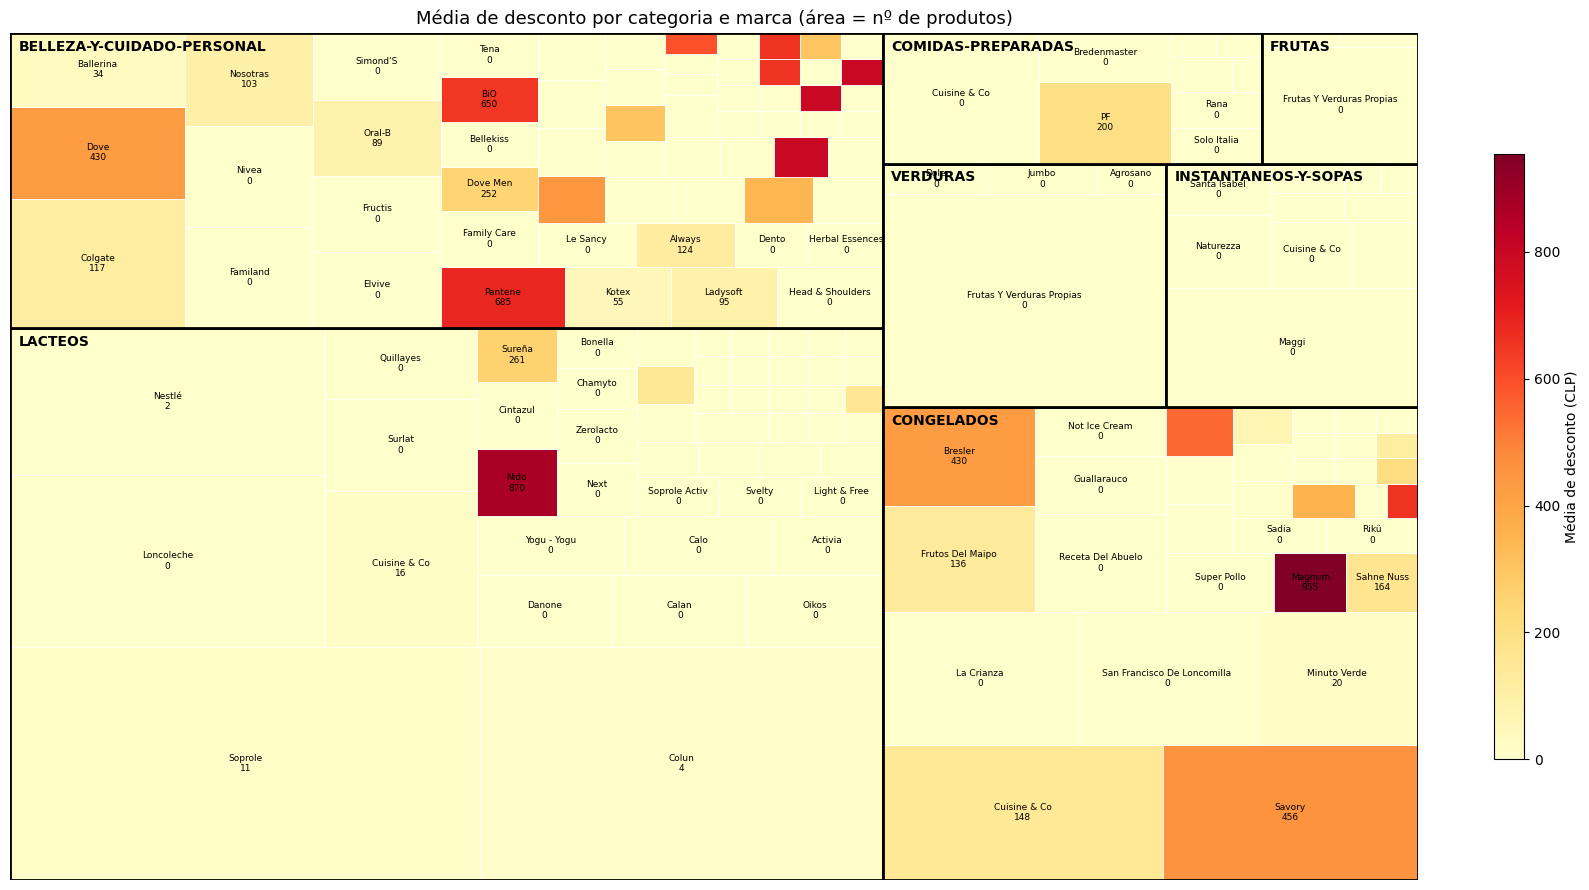

In [15]:
# Versão estática (PNG) do mesmo mapa, para entrega como imagem
import matplotlib as mpl
cats = mapa.groupby('Categoria').agg(p=('produtos', 'sum')).sort_values('p', ascending=False)
norm = mpl.colors.Normalize(0, mapa['desconto_medio'].max()); cmap = plt.cm.YlOrRd
fig, ax = plt.subplots(figsize=(16, 9)); ax.set_axis_off()
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
rects = squarify.squarify(squarify.normalize_sizes(cats['p'].tolist(), 100, 100), 0, 0, 100, 100)
for (cat, row), r in zip(cats.iterrows(), rects):
    sub = mapa[mapa['Categoria'] == cat].sort_values('produtos', ascending=False)
    inner = squarify.squarify(squarify.normalize_sizes(sub['produtos'].tolist(), r['dx'], r['dy']),
                              r['x'], r['y'], r['dx'], r['dy'])
    for (_, m), s in zip(sub.iterrows(), inner):
        ax.add_patch(plt.Rectangle((s['x'], s['y']), s['dx'], s['dy'],
                     fc=cmap(norm(m['desconto_medio'])), ec='white', lw=.6))
        if s['dx'] > 5 and s['dy'] > 3.5:
            ax.text(s['x'] + s['dx']/2, s['y'] + s['dy']/2, f"{m['Marca']}\n{m['desconto_medio']:.0f}",
                    ha='center', va='center', fontsize=6.5)
    ax.add_patch(plt.Rectangle((r['x'], r['y']), r['dx'], r['dy'], fill=False, ec='black', lw=2))
    ax.text(r['x'] + 0.6, r['y'] + r['dy'] - 0.8, cat.upper(), va='top', fontsize=10, weight='bold')
cb = plt.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, fraction=.02)
cb.set_label('Média de desconto (CLP)')
ax.set_title('Média de desconto por categoria e marca (área = nº de produtos)', fontsize=13)
plt.tight_layout(); plt.savefig('graficos/03_mapa_desconto_categoria_marca.png', dpi=150); plt.show()

In [16]:
mapa.sort_values('desconto_medio', ascending=False).head(10)

,Categoria,Marca,desconto_medio,produtos
78,congelados,Magnum,955.00,4
142,lacteos,Nido,869.80,5
39,belleza-y-cuidado-personal,Oral Fresh,797.00,1
48,belleza-y-cuidado-personal,Rexona Men Clinical,795.00,1
46,belleza-y-cuidado-personal,Rexona Clinical,795.00,2
41,belleza-y-cuidado-personal,Pantene,684.86,7
45,belleza-y-cuidado-personal,Rexona,660.00,1
47,belleza-y-cuidado-personal,Rexona Men,660.00,1
79,congelados,Mega,657.00,1
6,belleza-y-cuidado-personal,BiO,650.00,4


**Leitura:** a cor mostra o desconto médio de cada marca dentro da categoria; o tamanho, quantos produtos ela tem. As células mais escuras (descontos médios acima de ~600 CLP) aparecem em marcas pontuais de `congelados` (ex.: Magnum), `belleza-y-cuidado-personal` (ex.: Pantene, BiO) e `lacteos` (Nido), enquanto a grande maioria das marcas tem desconto médio próximo de 0. O arquivo HTML permite passar o mouse e clicar para aprofundar em cada categoria.